In [1]:
!pip install optuna

In [2]:
# HYBRID XLM-RoBERTa + TF-IDF + STAT FEATURES WITH OPTUNA HYPERPARAMETER TUNING

## 1. Import required libraries
import pandas as pd
import numpy as np
import re
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, f1_score
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch.utils.data import Dataset, DataLoader
from torch import nn
from transformers import XLMRobertaTokenizer, XLMRobertaModel
from torch.optim import AdamW
from tqdm import tqdm
from torch.utils.tensorboard import SummaryWriter
import optuna
from optuna.trial import TrialState
import os
import warnings
warnings.filterwarnings("ignore")

## 2. Load datasets
train_df = pd.read_excel("train_data_with_codemixed_preprocessing.xlsx")
val_df = pd.read_excel("val_data_with_codemixed_preprocessing.xlsx")
test_df = pd.read_excel("test_data_with_codemixed_preprocessing.xlsx")

## 3. Feature extraction: TF-IDF and statistical features
def prepare_features(train_df, val_df, test_df, max_features=1000):
    tfidf = TfidfVectorizer(max_features=max_features)
    X_tfidf_train = tfidf.fit_transform(train_df['tweet_clean_codemixed']).toarray()
    X_tfidf_val = tfidf.transform(val_df['tweet_clean_codemixed']).toarray()
    X_tfidf_test = tfidf.transform(test_df['tweet_clean_codemixed']).toarray()

    def extract_stat_features(lang_seq):
        id_count = len(re.findall(r'\[id\]', lang_seq))
        en_count = len(re.findall(r'\[en\]', lang_seq))
        unk_count = len(re.findall(r'\[\?\?\]', lang_seq))
        total = id_count + en_count + unk_count
        return [total, id_count/total if total else 0, en_count/total if total else 0, unk_count/total if total else 0]

    X_stat_train = np.array([extract_stat_features(text) for text in train_df['lang_per_word']])
    X_stat_val = np.array([extract_stat_features(text) for text in val_df['lang_per_word']])
    X_stat_test = np.array([extract_stat_features(text) for text in test_df['lang_per_word']])

    scaler = StandardScaler()
    X_stat_train = scaler.fit_transform(X_stat_train)
    X_stat_val = scaler.transform(X_stat_val)
    X_stat_test = scaler.transform(X_stat_test)

    return X_tfidf_train, X_tfidf_val, X_tfidf_test, X_stat_train, X_stat_val, X_stat_test, tfidf, scaler

## 4. Dataset class
tokenizer = XLMRobertaTokenizer.from_pretrained("xlm-roberta-base")

class HybridDataset(Dataset):
    def __init__(self, texts, tfidf, stat, labels, max_length=128):
        self.encodings = tokenizer(texts.tolist(), padding=True, truncation=True,
                                 max_length=max_length, return_tensors='pt')
        self.tfidf = torch.tensor(tfidf, dtype=torch.float32)
        self.stat = torch.tensor(stat, dtype=torch.float32)
        self.labels = torch.tensor(labels.tolist(), dtype=torch.long)

    def __getitem__(self, idx):
        item = {key: val[idx] for key, val in self.encodings.items()}
        item['tfidf'] = self.tfidf[idx]
        item['stat'] = self.stat[idx]
        item['labels'] = self.labels[idx]
        return item

    def __len__(self):
        return len(self.labels)

## 5. Hybrid model with configurable architecture
class HybridModel(nn.Module):
    def __init__(self, tfidf_hidden_dim=128, stat_hidden_dim=16, classifier_hidden_dim=128,
                 dropout_rate=0.3, tfidf_features=1000):
        super().__init__()
        self.xlm = XLMRobertaModel.from_pretrained("xlm-roberta-base")

        # Freeze some layers for efficiency (optional)
        for param in self.xlm.embeddings.parameters():
            param.requires_grad = False
        for layer in self.xlm.encoder.layer[:6]:  # Freeze first 6 layers
            for param in layer.parameters():
                param.requires_grad = False

        self.tfidf_layer = nn.Sequential(
            nn.Linear(tfidf_features, tfidf_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout_rate)
        )

        self.stat_layer = nn.Sequential(
            nn.Linear(4, stat_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout_rate)
        )

        self.classifier = nn.Sequential(
            nn.Linear(768 + tfidf_hidden_dim + stat_hidden_dim, classifier_hidden_dim),
            nn.ReLU(),
            nn.Dropout(dropout_rate),
            nn.Linear(classifier_hidden_dim, 2)
        )

    def forward(self, input_ids, attention_mask, tfidf, stat):
        xlm_out = self.xlm(input_ids=input_ids, attention_mask=attention_mask).last_hidden_state[:, 0, :]
        tfidf_out = self.tfidf_layer(tfidf)
        stat_out = self.stat_layer(stat)
        combined = torch.cat([xlm_out, tfidf_out, stat_out], dim=1)
        return self.classifier(combined)

## 6. Training function for Optuna
def train_model(trial, train_df, val_df, device):
    # Hyperparameters to optimize
    learning_rate = trial.suggest_float("learning_rate", 1e-5, 5e-5, log=True)
    batch_size = trial.suggest_categorical("batch_size", [16, 32, 64])
    max_length = trial.suggest_int("max_length", 64, 256, step=32)
    tfidf_features = trial.suggest_int("tfidf_features", 500, 2000, step=250)

    tfidf_hidden_dim = trial.suggest_int("tfidf_hidden_dim", 64, 256, step=32)
    stat_hidden_dim = trial.suggest_int("stat_hidden_dim", 8, 32, step=8)
    classifier_hidden_dim = trial.suggest_int("classifier_hidden_dim", 64, 256, step=32)
    dropout_rate = trial.suggest_float("dropout_rate", 0.1, 0.5)
    weight_decay = trial.suggest_float("weight_decay", 1e-5, 1e-3, log=True)

    # Prepare features with current hyperparameters
    X_tfidf_train, X_tfidf_val, _, X_stat_train, X_stat_val, _, _, _ = prepare_features(
        train_df, val_df, val_df, max_features=tfidf_features
    )

    # Create datasets
    train_data = HybridDataset(train_df['tweet_for_model'], X_tfidf_train, X_stat_train,
                              train_df['label'], max_length=max_length)
    val_data = HybridDataset(val_df['tweet_for_model'], X_tfidf_val, X_stat_val,
                            val_df['label'], max_length=max_length)

    train_loader = DataLoader(train_data, batch_size=batch_size, shuffle=True)
    val_loader = DataLoader(val_data, batch_size=batch_size)

    # Initialize model
    model = HybridModel(
        tfidf_hidden_dim=tfidf_hidden_dim,
        stat_hidden_dim=stat_hidden_dim,
        classifier_hidden_dim=classifier_hidden_dim,
        dropout_rate=dropout_rate,
        tfidf_features=tfidf_features
    ).to(device)

    optimizer = AdamW(model.parameters(), lr=learning_rate, weight_decay=weight_decay)
    loss_fn = nn.CrossEntropyLoss()

    best_val_f1 = 0
    patience = 5
    counter = 0

    # Training loop (reduced epochs for efficiency)
    for epoch in range(5):  # Reduced epochs for hyperparameter search
        model.train()
        train_loss = 0

        for batch in train_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            tfidf = batch['tfidf'].to(device)
            stat = batch['stat'].to(device)
            labels = batch['labels'].to(device)

            optimizer.zero_grad()
            outputs = model(input_ids, attention_mask, tfidf, stat)
            loss = loss_fn(outputs, labels)
            loss.backward()

            # Gradient clipping
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
            optimizer.step()
            train_loss += loss.item()

        # Validation
        model.eval()
        val_preds, val_labels = [], []
        val_loss = 0

        with torch.no_grad():
            for batch in val_loader:
                input_ids = batch['input_ids'].to(device)
                attention_mask = batch['attention_mask'].to(device)
                tfidf = batch['tfidf'].to(device)
                stat = batch['stat'].to(device)
                labels = batch['labels'].to(device)

                outputs = model(input_ids, attention_mask, tfidf, stat)
                loss = loss_fn(outputs, labels)
                val_loss += loss.item()

                preds = torch.argmax(outputs, dim=1)
                val_preds.extend(preds.cpu().numpy())
                val_labels.extend(labels.cpu().numpy())

        val_f1 = f1_score(val_labels, val_preds, average='weighted')

        # Report intermediate value for pruning
        trial.report(val_f1, epoch)

        # Handle pruning based on the intermediate value
        if trial.should_prune():
            raise optuna.exceptions.TrialPruned()

        if val_f1 > best_val_f1:
            best_val_f1 = val_f1
            counter = 0
        else:
            counter += 1
            if counter >= patience:
                break

    return best_val_f1

## 7. Optuna optimization
def optimize_hyperparameters(train_df, val_df, n_trials=50):
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")

    # Create study
    study = optuna.create_study(
        direction="maximize",
        pruner=optuna.pruners.MedianPruner(
            n_startup_trials=5,
            n_warmup_steps=2,
            interval_steps=1
        )
    )

    # Optimize
    study.optimize(
        lambda trial: train_model(trial, train_df, val_df, device),
        n_trials=n_trials,
        timeout=3600,  # 1 hour timeout
        show_progress_bar=True
    )

    return study

## 8. Run hyperparameter optimization
print("Starting hyperparameter optimization...")
study = optimize_hyperparameters(train_df, val_df, n_trials=30)

print("Best trial:")
trial = study.best_trial
print(f"Value: {trial.value}")
print("Params: ")
for key, value in trial.params.items():
    print(f"    {key}: {value}")

## 9. Train final model with best hyperparameters
print("\nTraining final model with best hyperparameters...")
best_params = study.best_params
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Prepare features with best hyperparameters
X_tfidf_train, X_tfidf_val, X_tfidf_test, X_stat_train, X_stat_val, X_stat_test, tfidf, scaler = prepare_features(
    train_df, val_df, test_df, max_features=best_params['tfidf_features']
)

# Create datasets with best hyperparameters
train_data = HybridDataset(train_df['tweet_for_model'], X_tfidf_train, X_stat_train,
                          train_df['label'], max_length=best_params['max_length'])
val_data = HybridDataset(val_df['tweet_for_model'], X_tfidf_val, X_stat_val,
                        val_df['label'], max_length=best_params['max_length'])
test_data = HybridDataset(test_df['tweet_for_model'], X_tfidf_test, X_stat_test,
                         test_df['label'], max_length=best_params['max_length'])

train_loader = DataLoader(train_data, batch_size=best_params['batch_size'], shuffle=True)
val_loader = DataLoader(val_data, batch_size=best_params['batch_size'])
test_loader = DataLoader(test_data, batch_size=best_params['batch_size'])

# Initialize final model with best hyperparameters
model = HybridModel(
    tfidf_hidden_dim=best_params['tfidf_hidden_dim'],
    stat_hidden_dim=best_params['stat_hidden_dim'],
    classifier_hidden_dim=best_params['classifier_hidden_dim'],
    dropout_rate=best_params['dropout_rate'],
    tfidf_features=best_params['tfidf_features']
).to(device)

optimizer = AdamW(model.parameters(), lr=best_params['learning_rate'],
                 weight_decay=best_params['weight_decay'])
loss_fn = nn.CrossEntropyLoss()

## 10. Training loop with best hyperparameters
writer = SummaryWriter(log_dir="runs/hybrid_xlmr_optimized")
best_val_loss = float("inf")
train_loss_hist, val_loss_hist, train_acc_hist, val_acc_hist = [], [], [], []
patience = 50
counter = 0

for epoch in range(50):  # More epochs for final training
    model.train()
    train_loss, train_correct, train_total = 0, 0, 0

    for batch in tqdm(train_loader, desc=f"Epoch {epoch+1} - Train"):
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        tfidf = batch['tfidf'].to(device)
        stat = batch['stat'].to(device)
        labels = batch['labels'].to(device)

        optimizer.zero_grad()
        outputs = model(input_ids, attention_mask, tfidf, stat)
        loss = loss_fn(outputs, labels)
        loss.backward()

        # Gradient clipping
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
        optimizer.step()

        train_loss += loss.item()
        preds = outputs.argmax(dim=1)
        train_correct += (preds == labels).sum().item()
        train_total += labels.size(0)

    train_loss /= len(train_loader)
    train_acc = train_correct / train_total
    train_loss_hist.append(train_loss)
    train_acc_hist.append(train_acc)

    writer.add_scalar("Loss/Train", train_loss, epoch)
    writer.add_scalar("Accuracy/Train", train_acc, epoch)

    # Validation
    model.eval()
    val_loss, val_correct, val_total = 0, 0, 0
    with torch.no_grad():
        for batch in val_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            tfidf = batch['tfidf'].to(device)
            stat = batch['stat'].to(device)
            labels = batch['labels'].to(device)

            outputs = model(input_ids, attention_mask, tfidf, stat)
            loss = loss_fn(outputs, labels)
            val_loss += loss.item()
            preds = outputs.argmax(dim=1)
            val_correct += (preds == labels).sum().item()
            val_total += labels.size(0)

    val_loss /= len(val_loader)
    val_acc = val_correct / val_total
    val_loss_hist.append(val_loss)
    val_acc_hist.append(val_acc)

    writer.add_scalar("Loss/Val", val_loss, epoch)
    writer.add_scalar("Accuracy/Val", val_acc, epoch)

    print(f"Epoch {epoch+1}: Train Loss={train_loss:.4f}, Train Acc={train_acc:.4f} | Val Loss={val_loss:.4f}, Val Acc={val_acc:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(model.state_dict(), "best_model_optimized.pt")
        counter = 0
    else:
        counter += 1
        if counter >= patience:
            print("Early stopping!")
            break

## 11. Load best model and make predictions
model.load_state_dict(torch.load("best_model_optimized.pt"))

def predict_and_save(model, data_loader, df, file_path):
    model.eval()
    preds, probs = [], []

    with torch.no_grad():
        for batch in data_loader:
            input_ids = batch['input_ids'].to(device)
            attention_mask = batch['attention_mask'].to(device)
            tfidf = batch['tfidf'].to(device)
            stat = batch['stat'].to(device)

            outputs = model(input_ids, attention_mask, tfidf, stat)
            prob = torch.softmax(outputs, dim=1)[:, 1].cpu().numpy()
            pred = torch.argmax(outputs, dim=1).cpu().numpy()
            preds.extend(pred)
            probs.extend(prob)

    df['predicted_label'] = preds
    df['predicted_prob'] = probs
    df['is_correct'] = df['label'] == df['predicted_label']
    df.to_excel(file_path, index=False)

predict_and_save(model, train_loader, train_df, "train_data_with_preds_optimized.xlsx")
predict_and_save(model, val_loader, val_df, "val_data_with_preds_optimized.xlsx")
predict_and_save(model, test_loader, test_df, "test_data_with_preds_optimized.xlsx")

## 12. Final evaluation
print("\n=== FINAL EVALUATION WITH OPTIMIZED HYPERPARAMETERS ===")
print("Train Report:")
print(classification_report(train_df['label'], train_df['predicted_label'], digits=4))
print("\nVal Report:")
print(classification_report(val_df['label'], val_df['predicted_label'], digits=4))
print("\nTest Report:")
print(classification_report(test_df['label'], test_df['predicted_label'], digits=4))
print(f"\nROC AUC (test): {roc_auc_score(test_df['label'], test_df['predicted_prob']):.4f}")



## 14. Save hyperparameter optimization results
results_df = study.trials_dataframe()
results_df.to_csv("optuna_optimization_results.csv", index=False)

print(f"\nOptimization completed!")
print(f"Best validation F1 score: {study.best_value:.4f}")
print(f"Total trials: {len(study.trials)}")
print(f"Completed trials: {len([t for t in study.trials if t.state == TrialState.COMPLETE])}")
print(f"Pruned trials: {len([t for t in study.trials if t.state == TrialState.PRUNED])}")

writer.close()

[I 2026-06-06 20:09:15,806] A new study created in memory with name: no-name-e5491bf7-44f5-46bc-b31d-c9f973ef0505


Starting hyperparameter optimization...
Using device: cuda


  0%|          | 0/30 [00:00<?, ?it/s]

[I 2026-06-07 07:37:13,658] Trial 0 finished with value: 0.9364967890321254 and parameters: {'learning_rate': 2.795315641411306e-05, 'batch_size': 64, 'max_length': 160, 'tfidf_features': 2000, 'tfidf_hidden_dim': 64, 'stat_hidden_dim': 16, 'classifier_hidden_dim': 128, 'dropout_rate': 0.370985411930691, 'weight_decay': 4.804482518523465e-05}. Best is trial 0 with value: 0.9364967890321254.
Best trial:
Value: 0.9364967890321254
Params: 
    learning_rate: 2.795315641411306e-05
    batch_size: 64
    max_length: 160
    tfidf_features: 2000
    tfidf_hidden_dim: 64
    stat_hidden_dim: 16
    classifier_hidden_dim: 128
    dropout_rate: 0.370985411930691
    weight_decay: 4.804482518523465e-05

Training final model with best hyperparameters...


Epoch 1 - Train: 100%|███████████████████████████████████████████████████████████████| 137/137 [00:31<00:00,  4.29it/s]


...

Epoch 48: Train Loss=0.0122, Train Acc=0.9966 | Val Loss=0.5786, Val Acc=0.9219


Epoch 49 - Train: 100%|██████████████████████████████████████████████████████████████| 137/137 [00:31<00:00,  4.30it/s]


Epoch 49: Train Loss=0.0078, Train Acc=0.9977 | Val Loss=0.6048, Val Acc=0.9292


Epoch 50 - Train: 100%|██████████████████████████████████████████████████████████████| 137/137 [00:31<00:00,  4.38it/s]


Epoch 50: Train Loss=0.0088, Train Acc=0.9971 | Val Loss=0.5675, Val Acc=0.9333

=== FINAL EVALUATION WITH OPTIMIZED HYPERPARAMETERS ===
Train Report:
              precision    recall  f1-score   support

           0     0.4973    0.5183    0.5076      4362
           1     0.5004    0.4793    0.4896      4390

    accuracy                         0.4987      8752
   macro avg     0.4988    0.4988    0.4986      8752
weighted avg     0.4988    0.4987    0.4986      8752


Val Report:
              precision    recall  f1-score   support

           0     0.9101    0.9652    0.9368      1091
           1     0.9632    0.9053    0.9333      1098

    accuracy                         0.9351      2189
   macro avg     0.9366    0.9352    0.9351      2189
weighted avg     0.9367    0.9351    0.9351      2189


Test Report:
              precision    recall  f1-score   support

           0     0.9211    0.9501    0.9354      1363
           1     0.9489    0.9192    0.9338      1373

    

<Figure size 1000x600 with 0 Axes>

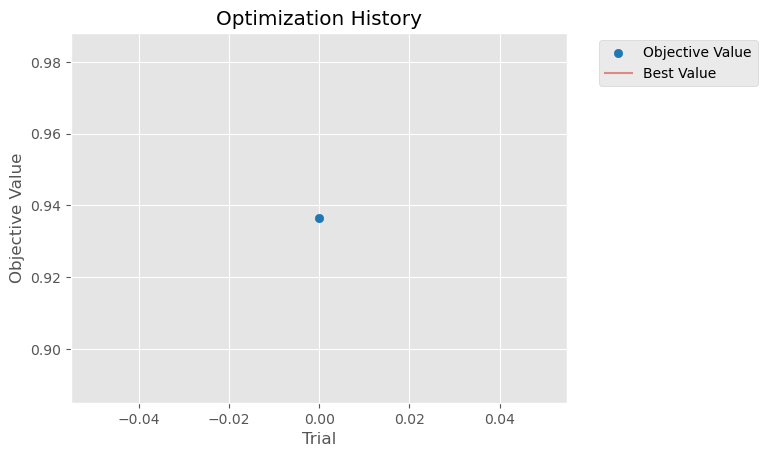

In [3]:
# Hyperparameter optimization history
# Set figure size to make the plot larger
plt.figure(figsize=(10, 6))

optuna.visualization.matplotlib.plot_optimization_history(study)
plt.title("Optimization History")
# Show the plot
plt.show()

In [4]:
import matplotlib.pyplot as plt
import optuna.visualization

# Set figure size to make the plot larger
plt.figure(figsize=(10, 6))

# Plot parameter importance using Optuna
optuna.visualization.matplotlib.plot_param_importances(study)

# Optional: Add title--
#plt.title("Parameter Importance")

# Show the plot
plt.show()


ValueError: Cannot evaluate parameter importances with only a single trial.

<Figure size 1000x600 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Set figure size to make the plot larger
plt.figure(figsize=(10, 6))

# ROC Curve
fpr, tpr, _ = roc_curve(test_df['label'], test_df['predicted_prob'])

# Plot ROC curve
plt.plot(fpr, tpr, label=f'ROC Curve (AUC = {roc_auc_score(test_df["label"], test_df["predicted_prob"]):.4f})')
plt.plot([0, 1], [0, 1], 'k--')

# Set axis limits
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])

# Add labels and title
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Optimized)')

# Show legend
plt.legend()

# Show the plot
plt.show()




In [ ]:
#Training curves
# Set figure size to make the plot larger
plt.figure(figsize=(10, 6))

plt.plot(train_loss_hist, label="Train Loss")
plt.plot(val_loss_hist, label="Val Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.title("Loss over Epochs (Optimized)")
# Show the plot
plt.show()

In [ ]:
# Set figure size to make the plot larger
plt.figure(figsize=(10, 6))

plt.plot(train_acc_hist, label="Train Accuracy")
plt.plot(val_acc_hist, label="Val Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy over Epochs (Optimized)")
# Show the plot
plt.show()

In [ ]:
# Confusion Matrix
plt.figure(figsize=(10, 6))
labels = ['Non-Bullying', 'Bullying']
cm = confusion_matrix(test_df['label'], test_df['predicted_label'])
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=labels, yticklabels=labels)
plt.title("Test Set Confusion Matrix (Optimized)")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
# Show the plot
plt.show()